# 03 — Compare products

Side-by-side: **cost to hit a target chase probability** and **EV edge vs retail**.

Print-run products (Grand Master Rare) are evaluated at each scenario in their YAML. Fixed-rate products use `hits_per_box`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
if ROOT.name != "notebooks" and (ROOT / "notebooks").is_dir():
    ROOT = ROOT / "notebooks"
sys.path.insert(0, str(ROOT))

from poke_sim import (
    boxes_for_probability,
    edge,
    edge_pct,
    load_products,
    p_from_print_run,
    p_from_rate,
    pack_ev_from_slots,
)

TARGET = 0.50
MODE = "any"  # for print_run_serial: any vs specific

In [2]:
rows = []
for product in load_products():
    retail = product["retail_price_sek"]
    packs = product.get("packs_per_box")
    unit_note = f"{packs}-pack box" if packs else product.get("unit", "box")

    # EV from YAML slots if present
    if "ev" in product and "slots" in product["ev"]:
        ev = pack_ev_from_slots(product["ev"]["slots"])
        # Pokémon YAML slots are per-pack; scale to box when packs_per_box is set and slots look pack-sized
        if product.get("game") == "pokemon" and packs:
            box_ev = ev * packs
        else:
            box_ev = ev
        ev_edge = edge(box_ev, retail)
        ev_edge_pct = edge_pct(box_ev, retail)
    else:
        box_ev = ev_edge = ev_edge_pct = float("nan")

    chase = product.get("chase", {})
    ctype = chase.get("type")

    if ctype == "print_run_serial":
        serials = chase["total_serials_region"] if MODE == "any" else chase["serials_per_card"]
        for n in chase.get("print_run_boxes_scenarios", []):
            p_box = p_from_print_run(serials, n)
            boxes = boxes_for_probability(p_box, TARGET)
            rows.append({
                "product": product["name"],
                "game": product.get("game"),
                "unit_note": unit_note,
                "chase": f"{chase.get('label', chase.get('name'))} [{MODE}]",
                "scenario": f"print_run={n:,}",
                "p_box": p_box,
                "boxes_for_target": boxes,
                "spend_for_target": boxes * retail,
                "retail_sek": retail,
                "box_ev_sek": box_ev,
                "ev_edge_sek": ev_edge,
                "ev_edge_pct": ev_edge_pct,
            })
    elif ctype == "fixed_rate":
        p_box = p_from_rate(chase["hits_per_box"])
        boxes = boxes_for_probability(p_box, TARGET)
        rows.append({
            "product": product["name"],
            "game": product.get("game"),
            "unit_note": unit_note,
            "chase": chase.get("label", chase.get("name")),
            "scenario": f"hits/box={chase['hits_per_box']}",
            "p_box": p_box,
            "boxes_for_target": boxes,
            "spend_for_target": boxes * retail,
            "retail_sek": retail,
            "box_ev_sek": box_ev,
            "ev_edge_sek": ev_edge,
            "ev_edge_pct": ev_edge_pct,
        })
    else:
        rows.append({
            "product": product["name"],
            "game": product.get("game"),
            "unit_note": unit_note,
            "chase": "(none)",
            "scenario": "—",
            "p_box": float("nan"),
            "boxes_for_target": float("nan"),
            "spend_for_target": float("nan"),
            "retail_sek": retail,
            "box_ev_sek": box_ev,
            "ev_edge_sek": ev_edge,
            "ev_edge_pct": ev_edge_pct,
        })

compare = pd.DataFrame(rows)
compare = compare.sort_values(["spend_for_target", "product"], na_position="last")
print(f"Target hit probability: {100*TARGET:.0f}% | MODE={MODE}")
compare

Target hit probability: 50% | MODE=any


,product,game,unit_note,chase,scenario,p_box,boxes_for_target,spend_for_target,retail_sek,box_ev_sek,ev_edge_sek,ev_edge_pct
7,Sample Pokémon Booster Box,pokemon,36-pack box,Special Illustration Rare (placeholder),hits/box=0.5,0.393469,2,3600,1800,1116.0,-684.0,-0.380000
3,Magnificent Monsters,yugioh,3-pack box,Grand Master Rare (any of 18) [any],"print_run=50,000",0.036000,19,7600,400,240.0,-160.0,-0.400000
0,Magnificent Maestros,yugioh,3-pack box,Grand Master Rare (any of 18) [any],"print_run=80,000",0.022500,31,13020,420,1110.0,690.0,1.642857
4,Magnificent Monsters,yugioh,3-pack box,Grand Master Rare (any of 18) [any],"print_run=100,000",0.018000,39,15600,400,240.0,-160.0,-0.400000
1,Magnificent Maestros,yugioh,3-pack box,Grand Master Rare (any of 18) [any],"print_run=150,000",0.012000,58,24360,420,1110.0,690.0,1.642857
5,Magnificent Monsters,yugioh,3-pack box,Grand Master Rare (any of 18) [any],"print_run=200,000",0.009000,77,30800,400,240.0,-160.0,-0.400000
2,Magnificent Maestros,yugioh,3-pack box,Grand Master Rare (any of 18) [any],"print_run=250,000",0.007200,96,40320,420,1110.0,690.0,1.642857
6,Magnificent Monsters,yugioh,3-pack box,Grand Master Rare (any of 18) [any],"print_run=500,000",0.003600,193,77200,400,240.0,-160.0,-0.400000


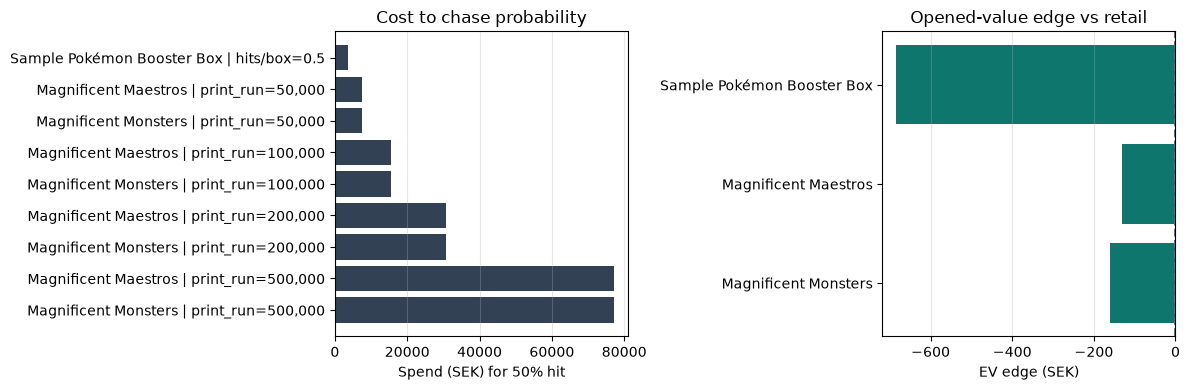

In [3]:
# Rank by spend to target (finite rows only)
ranked = compare.dropna(subset=["spend_for_target"]).copy()
ranked["label"] = ranked["product"] + " | " + ranked["scenario"].astype(str)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].barh(ranked["label"], ranked["spend_for_target"], color="#334155")
axes[0].set_xlabel(f"Spend (SEK) for {100*TARGET:.0f}% hit")
axes[0].set_title("Cost to chase probability")
axes[0].invert_yaxis()
axes[0].grid(True, axis="x", alpha=0.3)

ev_rows = ranked.drop_duplicates(subset=["product"])
axes[1].barh(ev_rows["product"], ev_rows["ev_edge_sek"], color="#0f766e")
axes[1].axvline(0, color="#64748b", linestyle="--")
axes[1].set_xlabel("EV edge (SEK)")
axes[1].set_title("Opened-value edge vs retail")
axes[1].invert_yaxis()
axes[1].grid(True, axis="x", alpha=0.3)

fig.tight_layout()
plt.show()

### How to read this

- **Spend for target** on GMR rows swings wildly with print-run assumption — that uncertainty is the point.
- **EV edge** uses placeholder slot values; update YAMLs before using it for buy/skip.
- Pokémon sample uses a fixed SIR-style rate; swap in real set rates when you have them.